<a href="https://www.kaggle.com/code/nicapotato/road-accident-records?scriptVersionId=364866408" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Guided Severity Exploration — Road Accident Records
_Where fatal share actually moves: place and light, on a row-level Great Britain-style ledger_

***

**Programming Language:** Python in the Jupyter Notebook Environment

**Dataset:** [deeplumiere/accident-analysis-dataset](https://www.kaggle.com/datasets/deeplumiere/accident-analysis-dataset)

**Style counterpart:** [Guided Numeric and Text Exploration — E-Commerce](https://www.kaggle.com/code/nicapotato/guided-numeric-and-text-exploration-e-commerce)

**Code Navigation:** <br>
In the code, text after hashtags (`#`) are supportive explanations, not executed as code.

***

# Tables of Content:

**1. [Introduction](#Introduction)** <br>
**2. [Setup and Data Peek](#Setup)** <br>
**3. [Univariate Distributions](#Univariate)** <br>
**4. [Where the Fatal Share Rises](#Setting)** <br>
**5. [Light Inside Urban and Rural](#Light)** <br>
**6. [Correlations](#Correlations)** <br>
**7. [What Shifts the Fatal Rate](#Model)** <br>
**8. [What It Means — Working Synthesis](#Synthesis)** <br>

# **1. Introduction:** <a id="Introduction"></a> <br>
Each row is one published accident record: 670,679 rows, 14 columns, accident dates from 1 Jan 2019 through 31 Dec 2025. District names, carriageway types, and coordinates sit in Great Britain. Severity is `Slight`, `Serious`, or `Fatal`.

Two structural facts come before any rate. `Index` was stored in scientific notation, so the token `2.01E+12` alone covers 239,478 rows. It is not an accident key, and this notebook stays on the published row. The year counts also break: 2019–2022 each hold well over 140,000 rows, while 2023–2025 each hold about 3,300. Those three years are a thin extract. A drop in row count across that cliff is a coverage fact.

The question is which recorded setting moves the fatal share. Blank weather, road type, and surface values stay missing. They are incomplete fields, and this notebook leaves them blank.

# **2. Setup and Data Peek:** <a id="Setup"></a>

In [1]:
# General
import json
import numpy as np
import pandas as pd
from pathlib import Path

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Scientific / modeling helpers
from IPython.display import display
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

import kagglehub

# Set Plot Theme (same family as the guided series)
sns.set_theme(style="whitegrid")
PALETTE = ["#30a2da", "#fc4f30", "#e5ae38", "#6d904f", "#8b8b8b"]
sns.set_palette(PALETTE)
plt.rcParams["figure.figsize"] = (11, 5)

# Warnings
import warnings
warnings.filterwarnings("ignore")

# Wide table inspection in Jupyter cell outputs
pd.set_option("display.max_columns", 999)
pd.set_option("display.width", 220)


def park_legend(ax, title=""):
    ax.legend(
        title=title,
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        borderaxespad=0,
        frameon=False,
    )

**Code Explanation and Reasoning:** <br>
These packages fall into three buckets: *General*, *Visualization*, and *Scientific / modeling helpers*.

`pandas` / `numpy` hold the table; `matplotlib` / `seaborn` do the graphics; `scipy` tests a crosstab and rank correlations; `sklearn` fits one linear model on a hold-out split. `kagglehub` resolves the file both on Kaggle (`/kaggle/input/...`) and locally.

The five-color palette matches the guided series so sequential plots feel like one exploration. When a plot has a legend, `park_legend` places it to the right of the axes.

In [2]:
# Read the published accident file and check the grain before any rate.
CSV_BASENAME = "accident_data.csv"
KAGGLE_SLUG = "deeplumiere/accident-analysis-dataset"
SEV_ORDER = ["Slight", "Serious", "Fatal"]
LIGHT_ORDER = [
    "Daylight",
    "Darkness - lights lit",
    "Darkness - lights unlit",
    "Darkness - lighting unknown",
    "Darkness - no lighting",
]
EXPECTED = [
    "Index", "Accident_Severity", "Accident Date", "Latitude", "Light_Conditions",
    "District Area", "Longitude", "Number_of_Casualties", "Number_of_Vehicles",
    "Road_Surface_Conditions", "Road_Type", "Urban_or_Rural_Area",
    "Weather_Conditions", "Vehicle_Type",
]


def resolve_file(basename: str, slug: str = KAGGLE_SLUG) -> Path:
    kaggle_root = Path("/kaggle/input")
    if kaggle_root.exists():
        hits = sorted(kaggle_root.rglob(basename))
        assert hits, f"no {basename} under {kaggle_root}"
        return hits[0]
    local_data = Path("data") / basename
    if local_data.exists():
        return local_data
    root = Path(kagglehub.dataset_download(slug))
    hits = sorted(root.rglob(basename))
    assert hits, f"expected {basename} under {root}"
    return hits[0]


csv_path = resolve_file(CSV_BASENAME)
print("CSV:", csv_path)
df = pd.read_csv(csv_path, low_memory=False)
missing = set(EXPECTED) - set(df.columns)
assert not missing, sorted(missing)
assert df.shape == (670679, 14), df.shape

df["Accident Date"] = pd.to_datetime(df["Accident Date"], format="%d-%m-%Y")
assert df["Accident Date"].min() == pd.Timestamp("2019-01-01")
assert df["Accident Date"].max() == pd.Timestamp("2025-12-31")
df["year"] = df["Accident Date"].dt.year
df["Accident_Severity"] = pd.Categorical(df["Accident_Severity"], SEV_ORDER, ordered=True)

# Index collapsed under scientific notation. Keep the row; do not roll up on Index.
collapsed = int((df["Index"] == "2.01E+12").sum())
assert collapsed == 239478, collapsed
sci_share = float(df["Index"].astype(str).str.contains("E", regex=False).mean())
year_counts = df["year"].value_counts().sort_index()
assert int(year_counts.loc[2022]) == 144419
assert int(year_counts.loc[2023]) == 3443
assert int((df["Accident_Severity"] == "Fatal").sum()) == 8804

print("Dataframe Dimension: {} Rows, {} Columns".format(*df.shape))
print(f"Dates: {df['Accident Date'].min().date()} -> {df['Accident Date'].max().date()}")
print(f"Index values containing 'E': {sci_share:.1%} of rows; collapsed token 2.01E+12: {collapsed:,} rows")
print("Rows by year:")
print(year_counts.to_string())
print("Nulls (left missing):")
nulls = df.isnull().sum()
print(nulls[nulls > 0].to_string())
display(df.dtypes.to_frame("dtype"))
display(df.sample(5, random_state=7))

CSV: /kaggle/input/datasets/deeplumiere/accident-analysis-dataset/accident_data.csv
Dataframe Dimension: 670679 Rows, 15 Columns
Dates: 2019-01-01 -> 2025-12-31
Index values containing 'E': 41.7% of rows; collapsed token 2.01E+12: 239,478 rows
Rows by year:
year
2019    182115
2020    170591
2021    163554
2022    144419
2023      3443
2024      3352
2025      3205
Nulls (left missing):
Latitude                      25
Longitude                     26
Road_Surface_Conditions      742
Road_Type                   4580
Urban_or_Rural_Area           15
Weather_Conditions         14351


,dtype
Index,object
Accident_Severity,category
Accident Date,datetime64[ns]
Latitude,float64
Light_Conditions,object
District Area,object
Longitude,float64
Number_of_Casualties,int64
Number_of_Vehicles,int64
Road_Surface_Conditions,object


,Index,Accident_Severity,Accident Date,Latitude,Light_Conditions,District Area,Longitude,Number_of_Casualties,Number_of_Vehicles,Road_Surface_Conditions,Road_Type,Urban_or_Rural_Area,Weather_Conditions,Vehicle_Type,year
105224,2.01E+12,Slight,2019-12-22,52.569770,Daylight,Great Yarmouth,1.711897,1,1,Dry,Single carriageway,Urban,Fine no high winds,Car,2019
525827,201001LX50566,Slight,2022-06-26,51.429426,Daylight,Lambeth,-0.130805,2,2,Dry,Single carriageway,Urban,Fine no high winds,Car,2022
152969,2.01E+12,Slight,2019-06-03,50.940458,Daylight,South Somerset,-2.622801,1,2,Dry,Single carriageway,Rural,Fine no high winds,Motorcycle over 500cc,2019
448906,2.01E+12,Serious,2021-11-07,52.866275,Daylight,North Norfolk,1.357597,1,2,Dry,Single carriageway,Rural,Fine no high winds,Car,2021
511389,200997AB05603,Slight,2021-03-09,55.862724,Darkness - lighting unknown,Glasgow City,-4.236820,1,2,Dry,Single carriageway,Urban,Fine no high winds,Bus or coach (17 or more pass seats),2021


**Code Explanation and Reasoning:** <br>
Shape, the 14 published columns, the date span, the collapsed `Index` token, the 2022/2023 coverage break, and the fatal-row count are asserted before any chart. `Index` stays a string so a numeric cast cannot hide the scientific-notation collision.

Missing latitude, road type, surface, urban/rural, and weather values are counted and left as null. Later rate tables drop those rows for the column being grouped. That is a complete-case cut for that column, not a filled category.

In [3]:
unique_count = [
    [c, df[c].nunique(dropna=False), int(df[c].isnull().sum())] for c in EXPECTED
]
display(
    pd.DataFrame(unique_count, columns=["Column", "Unique", "Null"])
    .sort_values("Unique", ascending=False)
    .reset_index(drop=True)
)
display(
    df[["Number_of_Casualties", "Number_of_Vehicles", "Latitude", "Longitude"]]
    .describe()
    .round(2)
)
print("Severity share:")
print(df["Accident_Severity"].value_counts(normalize=True).reindex(SEV_ORDER).round(4).to_string())
print(f"Share of rows with exactly 1 casualty: {(df['Number_of_Casualties'] == 1).mean():.1%}")

,Column,Unique,Null
0,Longitude,538497,26
1,Latitude,519908,25
2,Index,431020,0
3,Accident Date,2556,0
4,District Area,422,0
5,Number_of_Casualties,36,0
6,Number_of_Vehicles,19,0
7,Vehicle_Type,16,0
8,Weather_Conditions,9,14351
9,Road_Surface_Conditions,6,742


,Number_of_Casualties,Number_of_Vehicles,Latitude,Longitude
count,670679.00,670679.00,670654.00,670653.00
mean,1.36,1.83,52.55,-1.43
std,0.82,0.72,1.41,1.38
min,1.00,1.00,49.91,-7.52
25%,1.00,1.00,51.49,-2.33
50%,1.00,2.00,52.32,-1.41
75%,1.00,2.00,53.45,-0.23
max,68.00,32.00,60.76,1.76


Severity share:
Accident_Severity
Slight     0.8533
Serious    0.1335
Fatal      0.0131
Share of rows with exactly 1 casualty: 76.3%


**Interpretation** <br>
The ledger is mostly slight injury: 85.3% slight, 13.4% serious, 1.3% fatal (8,804 fatal rows). Casualties are small — the median is 1, and 76.3% of rows record a single casualty — while the mean is pulled up by a long tail (maximum 68). Vehicles per row have median 2. District is a 422-level place name. `Index` has far fewer distinct values than rows because of the scientific-notation collapse, so it cannot define an accident.

# **3. Univariate Distributions:** <a id="Univariate"></a>

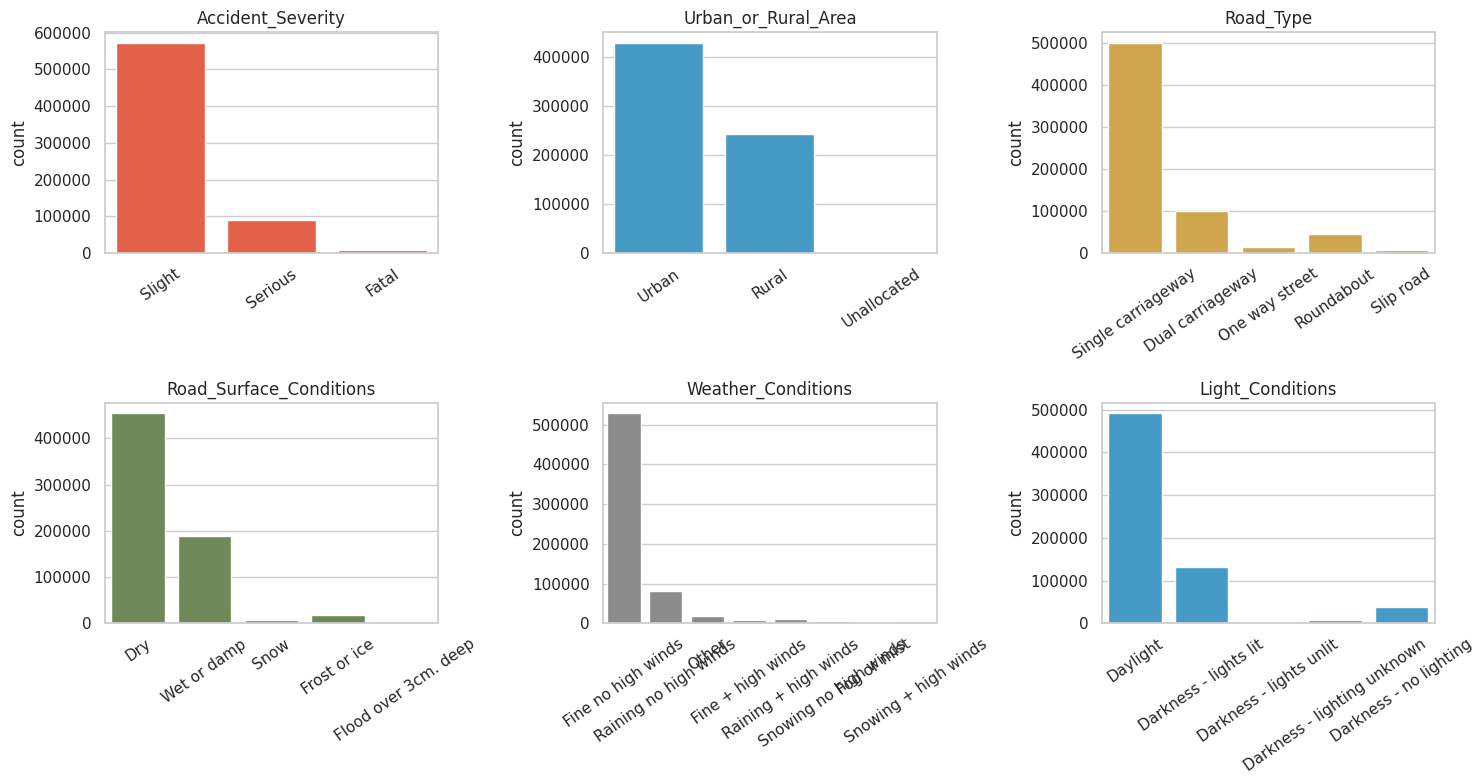

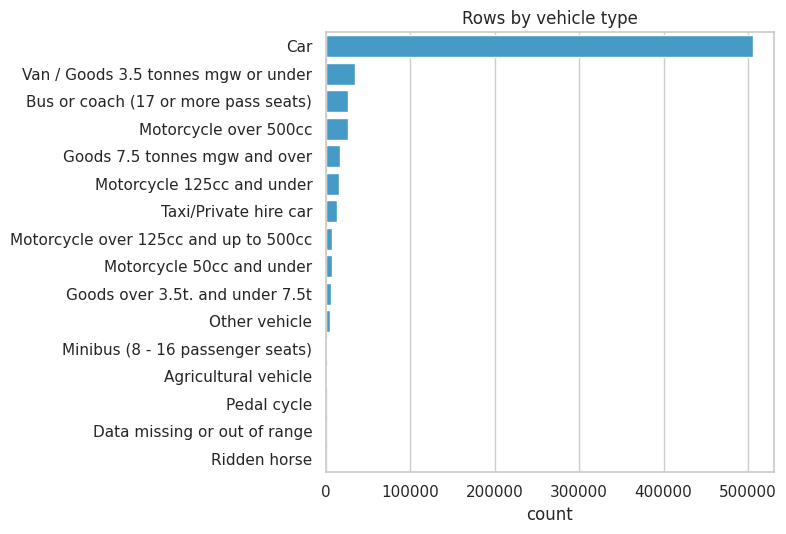

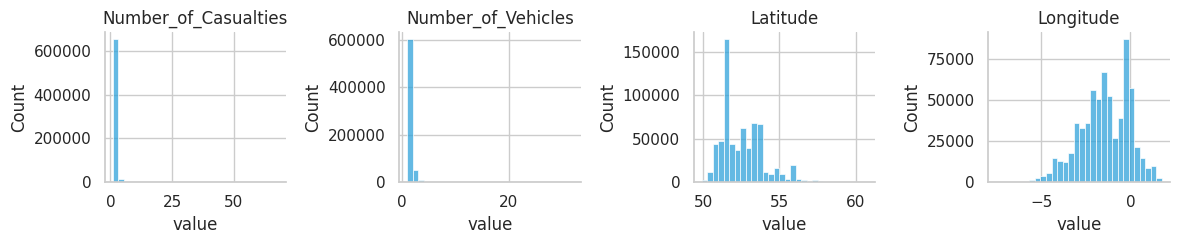

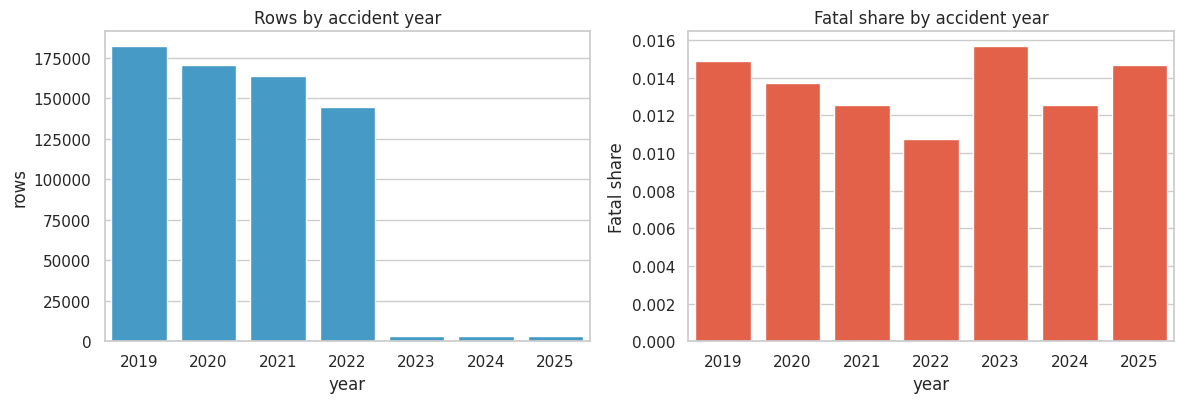

,year,rows,fatal_rate
0,2019,182115,0.0149
1,2020,170591,0.0137
2,2021,163554,0.0126
3,2022,144419,0.0107
4,2023,3443,0.0157
5,2024,3352,0.0125
6,2025,3205,0.0147


In [4]:
# Low-cardinality setting fields. High-cardinality Index and District stay out of the bars.
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
specs = [
    (axes[0, 0], "Accident_Severity", SEV_ORDER, "#fc4f30"),
    (axes[0, 1], "Urban_or_Rural_Area", None, "#30a2da"),
    (axes[0, 2], "Road_Type", None, "#e5ae38"),
    (axes[1, 0], "Road_Surface_Conditions", None, "#6d904f"),
    (axes[1, 1], "Weather_Conditions", None, "#8b8b8b"),
    (axes[1, 2], "Light_Conditions", LIGHT_ORDER, "#30a2da"),
]
for ax, col, order, color in specs:
    sns.countplot(data=df, x=col, order=order, color=color, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

vehicle_order = df["Vehicle_Type"].value_counts().index.tolist()
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.countplot(data=df, y="Vehicle_Type", order=vehicle_order, color="#30a2da", ax=ax)
ax.set_title("Rows by vehicle type")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

num_panel = ["Number_of_Casualties", "Number_of_Vehicles", "Latitude", "Longitude"]
melt = df[num_panel].melt(var_name="feature", value_name="value")
g = sns.FacetGrid(
    melt, col="feature", col_wrap=4, sharex=False, sharey=False, height=2.6, aspect=1.15,
)
g.map_dataframe(sns.histplot, x="value", bins=30, color="#30a2da")
g.set_titles("{col_name}")
plt.show()

yearly = (
    df.groupby("year", as_index=False)
    .agg(rows=("Accident_Severity", "size"),
         fatal_rate=("Accident_Severity", lambda s: float((s == "Fatal").mean())))
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.barplot(data=yearly, x="year", y="rows", color="#30a2da", ax=axes[0])
axes[0].set_title("Rows by accident year")
sns.barplot(data=yearly, x="year", y="fatal_rate", color="#fc4f30", ax=axes[1])
axes[1].set_title("Fatal share by accident year")
axes[1].set_ylabel("Fatal share")
plt.tight_layout()
plt.show()
display(yearly.assign(fatal_rate=lambda d: d["fatal_rate"].round(4)))

**Interpretation** <br>
Daylight, dry surface, fine weather, single carriageway, urban area, and car dominate the counts. Those are the common conditions, which is a separate fact from the fatal share inside each condition.

The numeric panels are tight around small casualty and vehicle counts, with coordinates spanning Great Britain. The year bars show the coverage cliff: 182,115 rows in 2019 down to 144,419 in 2022, then 3,443 in 2023. Fatal share inside the four dense years moves from 1.49% (2019) to 1.07% (2022). The 2023–2025 fatal shares sit on a few thousand rows each.

# **4. Where the Fatal Share Rises:** <a id="Setting"></a>


Urban_or_Rural_Area


,rows,fatal_rate,ksi_rate
Urban_or_Rural_Area,,,
Rural,"242,615",2.35%,17.97%
Urban,"428,038",0.72%,12.80%



Light_Conditions


,rows,fatal_rate,ksi_rate
Light_Conditions,,,
Darkness - no lighting,"37,981",4.31%,23.50%
Darkness - lights unlit,"2,581",1.82%,15.92%
Darkness - lights lit,"131,333",1.44%,16.25%
Darkness - lighting unknown,"6,583",1.06%,13.32%
Daylight,"492,201",1.05%,13.58%



Road_Type


,rows,fatal_rate,ksi_rate
Road_Type,,,
Dual carriageway,"100,926",1.83%,13.64%
Single carriageway,"499,607",1.33%,15.57%
One way street,"13,769",0.69%,12.91%
Slip road,"7,143",0.69%,9.38%
Roundabout,"44,654",0.32%,8.64%



Weather_Conditions


,rows,fatal_rate,ksi_rate
Weather_Conditions,,,
Fog or mist,"3,575",2.35%,15.94%
Fine + high winds,"8,695",2.08%,16.61%
Raining + high winds,"9,755",1.50%,14.67%
Fine no high winds,"528,789",1.37%,15.20%
Raining no high winds,"80,893",1.06%,12.96%
Other,"17,386",0.95%,11.45%
Snowing no high winds,"6,340",0.60%,9.65%
Snowing + high winds,895,0.34%,12.63%



Vehicle_Type


,rows,fatal_rate,ksi_rate
Vehicle_Type,,,
Pedal cycle,201,2.99%,22.89%
Minibus (8 - 16 passenger seats),"2,004",1.45%,15.42%
Van / Goods 3.5 tonnes mgw or under,"34,689",1.38%,14.70%
Motorcycle over 125cc and up to 500cc,"7,763",1.35%,14.58%
Motorcycle over 500cc,"26,036",1.33%,14.81%
Car,"505,502",1.32%,14.67%
Bus or coach (17 or more pass seats),"26,279",1.26%,14.30%
Other vehicle,"5,714",1.26%,15.00%
Goods 7.5 tonnes mgw and over,"17,579",1.25%,14.63%


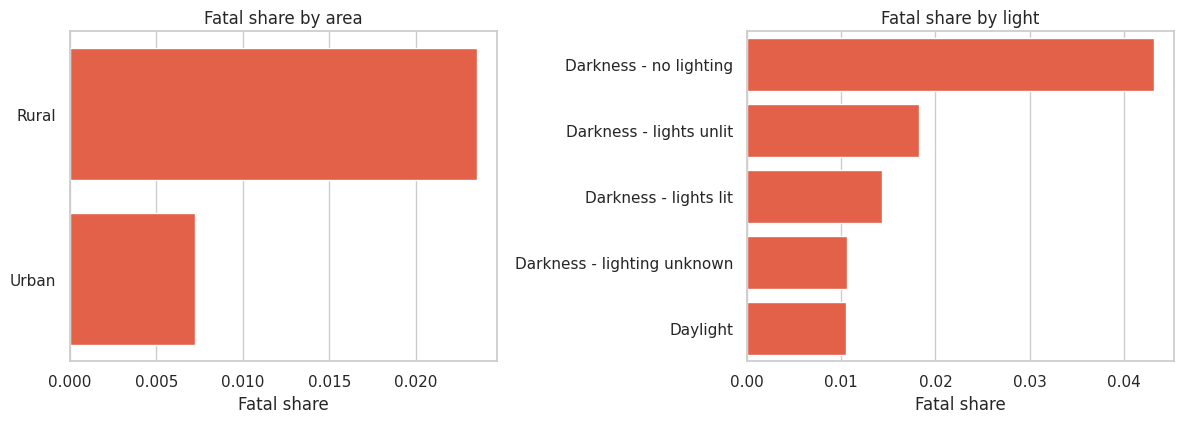

In [5]:
def severity_rates(frame: pd.DataFrame, col: str) -> pd.DataFrame:
    # Complete cases for this column only. Urban/rural keeps the two named areas.
    sub = frame.dropna(subset=[col]).copy()
    if col == "Urban_or_Rural_Area":
        sub = sub.loc[sub[col].isin(["Urban", "Rural"])]
    grouped = sub.groupby(col, observed=True)["Accident_Severity"]
    out = pd.DataFrame({
        "rows": grouped.size(),
        "fatal_rate": grouped.apply(lambda s: float((s == "Fatal").mean())),
        "ksi_rate": grouped.apply(lambda s: float(s.isin(["Fatal", "Serious"]).mean())),
    })
    return out.sort_values("fatal_rate", ascending=False)


for col in ["Urban_or_Rural_Area", "Light_Conditions", "Road_Type", "Weather_Conditions", "Vehicle_Type"]:
    tab = severity_rates(df, col)
    print(f"\n{col}")
    display(
        tab.style.format({"fatal_rate": "{:.2%}", "ksi_rate": "{:.2%}", "rows": "{:,.0f}"})
        .background_gradient(subset=["fatal_rate"], cmap="YlOrRd")
    )

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, col, title in [
    (axes[0], "Urban_or_Rural_Area", "Fatal share by area"),
    (axes[1], "Light_Conditions", "Fatal share by light"),
]:
    tab = severity_rates(df, col).reset_index()
    sns.barplot(data=tab, y=col, x="fatal_rate", color="#fc4f30", ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Fatal share")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

**Interpretation** <br>
Area and light move the fatal share. Rural rows are fatal 2.35% of the time, against 0.72% in urban rows. Killed-or-serious is 18.0% rural and 12.8% urban. Darkness with no lighting is fatal on 4.31% of rows, against 1.05% in daylight.

Road type is the next gap: dual carriageway 1.83%, single carriageway 1.33%, roundabout 0.32%. Weather is smaller. Fog is 2.35% fatal on 3,575 rows; snow with no high wind is 0.58% on 6,340 rows, below the dry-road share of 1.29%. Vehicle type, where the counts are large, sits near the car share of 1.32%. The pedal-cycle row is 2.99% fatal on 201 rows.

KSI is fatal plus serious, so it is a wider injury share than fatal alone. The same two settings — rural, and darkness with no lighting — lead both columns.

# **5. Light Inside Urban and Rural:** <a id="Light"></a>

Fatal share


Urban_or_Rural_Area,Rural,Urban
Light_Conditions,,
Daylight,1.94%,0.55%
Darkness - lights lit,2.34%,1.23%
Darkness - lights unlit,3.19%,1.00%
Darkness - lighting unknown,1.68%,0.69%
Darkness - no lighting,4.42%,2.26%


Row counts


Urban_or_Rural_Area,Rural,Urban
Light_Conditions,,
Daylight,"178,018","314,164"
Darkness - lights lit,"25,089","106,240"
Darkness - lights unlit,972,"1,608"
Darkness - lighting unknown,"2,507","4,076"
Darkness - no lighting,"36,029","1,950"


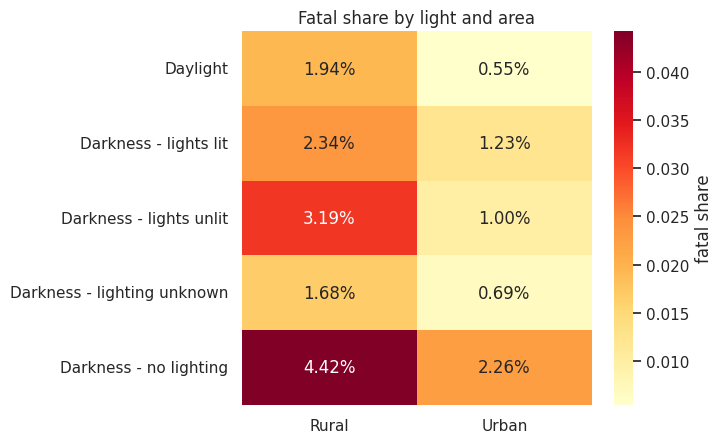

Urban/rural × severity chi-square=5,056, dof=2, p=0.000e+00
Rows in that table: 670,653


In [6]:
# Fatal share for every light × area cell that has both labels.
pair = df.dropna(subset=["Light_Conditions", "Urban_or_Rural_Area"]).copy()
pair = pair.loc[pair["Urban_or_Rural_Area"].isin(["Urban", "Rural"])]
fatal_flag = (pair["Accident_Severity"] == "Fatal").astype(float)
rate = pd.crosstab(
    pair["Light_Conditions"],
    pair["Urban_or_Rural_Area"],
    values=fatal_flag,
    aggfunc="mean",
).reindex(index=LIGHT_ORDER, columns=["Rural", "Urban"])
counts = pd.crosstab(
    pair["Light_Conditions"],
    pair["Urban_or_Rural_Area"],
).reindex(index=LIGHT_ORDER, columns=["Rural", "Urban"])
print("Fatal share")
display(rate.style.format("{:.2%}").background_gradient(cmap="YlOrRd", axis=None))
print("Row counts")
display(counts.style.format("{:,.0f}"))

fig, ax = plt.subplots(figsize=(7.2, 4.6))
sns.heatmap(rate, annot=True, fmt=".2%", cmap="YlOrRd", ax=ax, cbar_kws={"label": "fatal share"})
ax.set_title("Fatal share by light and area")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

area = df.loc[df["Urban_or_Rural_Area"].isin(["Urban", "Rural"])]
chi_tab = pd.crosstab(area["Urban_or_Rural_Area"], area["Accident_Severity"])
chi2, p_value, dof, _ = stats.chi2_contingency(chi_tab)
print(f"Urban/rural × severity chi-square={chi2:,.0f}, dof={dof}, p={p_value:.3e}")
print(f"Rows in that table: {int(chi_tab.values.sum()):,}")

**Interpretation** <br>
The two settings stack, and they are not the same rows. Unlit darkness is mostly rural (36,029 rural rows against 1,950 urban). Inside daylight, rural is still higher: 1.94% fatal against 0.55% urban. Inside unlit darkness, rural is 4.42% and urban is 2.26%.

The urban/rural severity table is huge, so the chi-square p-value is tiny. The useful number is the rate gap: about 1.6 percentage points on the fatal share between rural and urban overall, and a wider gap once the road is also unlit.

# **6. Correlations:** <a id="Correlations"></a>

Casualties vs vehicles: Spearman rho=0.226, p=0.000e+00
Casualty distribution by severity:


,median,mean,max
Accident_Severity,,,
Slight,1.0,1.33,47
Serious,1.0,1.47,45
Fatal,1.0,1.90,68


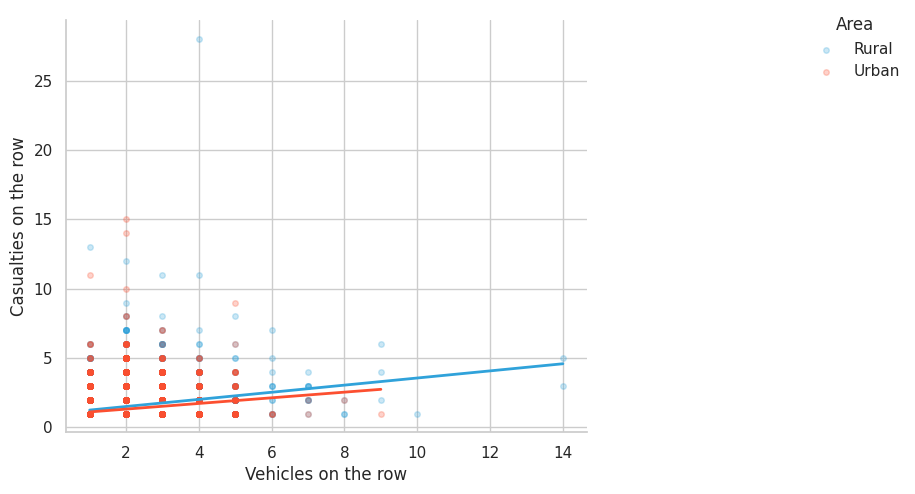

In [7]:
rho_cv, p_cv = stats.spearmanr(df["Number_of_Casualties"], df["Number_of_Vehicles"])
print(f"Casualties vs vehicles: Spearman rho={rho_cv:.3f}, p={p_cv:.3e}")
print("Casualty distribution by severity:")
display(
    df.groupby("Accident_Severity", observed=True)["Number_of_Casualties"]
    .agg(["median", "mean", "max"])
    .round(2)
)

# Scatter is a 25k-row window so the point cloud can be drawn. The Spearman above uses every row.
scatter = (
    df.dropna(subset=["Urban_or_Rural_Area"])
    .loc[lambda d: d["Urban_or_Rural_Area"].isin(["Urban", "Rural"])]
    .sample(25_000, random_state=7)
)
g = sns.lmplot(
    data=scatter,
    x="Number_of_Vehicles",
    y="Number_of_Casualties",
    hue="Urban_or_Rural_Area",
    hue_order=["Rural", "Urban"],
    height=5,
    aspect=1.25,
    ci=None,
    scatter_kws={"alpha": 0.25, "s": 16},
    line_kws={"lw": 2},
)
g.set_axis_labels("Vehicles on the row", "Casualties on the row")
sns.move_legend(g, "upper left", bbox_to_anchor=(1.02, 1), title="Area", frameon=False)
plt.show()

**Interpretation** <br>
More vehicles on a row go with more casualties, mildly: Spearman ρ is 0.226. The median casualty count is 1 in every severity, and the means step from 1.33 (slight) to 1.47 (serious) to 1.90 (fatal). Severity is a label on the row, while the casualty count is a small integer with a shared median.

The rural and urban lines on the scatter both rise. Area changes the fatal share more clearly than it changes the casualty-versus-vehicle slope.

# **7. What Shifts the Fatal Rate:** <a id="Model"></a>

Reference levels: {'Urban_or_Rural_Area': 'Rural', 'Light_Conditions': 'Darkness - lighting unknown', 'Road_Type': 'Dual carriageway'}
Rows in the model: 666,076; fatal share 1.317%
Hold-out R^2, setting model: 0.0077
Hold-out R^2, training-mean only: -0.0000


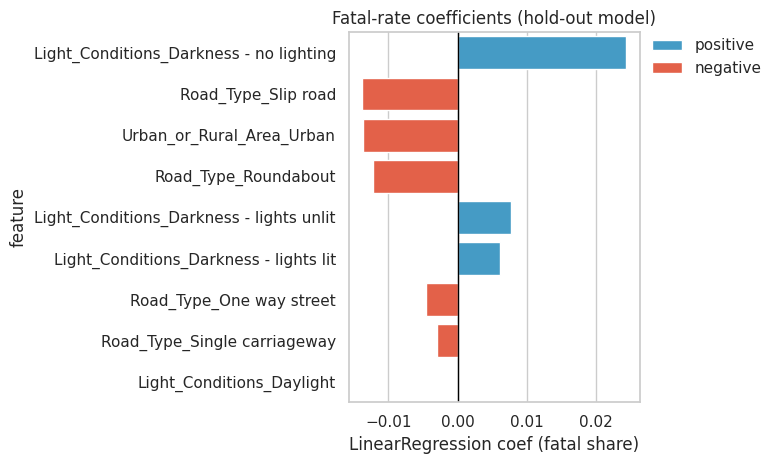

,coef
Light_Conditions_Darkness - no lighting,0.0243
Road_Type_Slip road,-0.0137
Urban_or_Rural_Area_Urban,-0.0136
Road_Type_Roundabout,-0.0122
Light_Conditions_Darkness - lights unlit,0.0078
Light_Conditions_Darkness - lights lit,0.0062
Road_Type_One way street,-0.0045
Road_Type_Single carriageway,-0.0029
Light_Conditions_Daylight,0.0001


In [8]:
# Linear probability model. Coefficients are percentage-point shifts in the mean fatal rate.
# Reference levels are the first sorted category: Rural, Darkness - lighting unknown, Dual carriageway.
model_df = df.dropna(subset=["Urban_or_Rural_Area", "Light_Conditions", "Road_Type"]).copy()
model_df = model_df.loc[model_df["Urban_or_Rural_Area"].isin(["Urban", "Rural"])]
model_df["fatal"] = (model_df["Accident_Severity"] == "Fatal").astype(int)
assert len(model_df) == 666076, len(model_df)

cats = ["Urban_or_Rural_Area", "Light_Conditions", "Road_Type"]
X = model_df[cats]
y = model_df["fatal"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=7)
pipe = Pipeline([
    ("pre", ColumnTransformer([("cat", OneHotEncoder(drop="first"), cats)])),
    ("lr", LinearRegression()),
])
pipe.fit(X_train, y_train)
ref = {col: sorted(model_df[col].astype(str).unique())[0] for col in cats}
print("Reference levels:", ref)
print(f"Rows in the model: {len(model_df):,}; fatal share {model_df['fatal'].mean():.3%}")
print(f"Hold-out R^2, setting model: {r2_score(y_test, pipe.predict(X_test)):.4f}")
print(f"Hold-out R^2, training-mean only: {r2_score(y_test, np.full(len(y_test), y_train.mean())):.4f}")

names = list(pipe.named_steps["pre"].named_transformers_["cat"].get_feature_names_out(cats))
coef = pd.Series(pipe.named_steps["lr"].coef_, index=names)
coef_sorted = coef.reindex(coef.abs().sort_values(ascending=False).index)
coef_plot = coef_sorted.rename("coef").rename_axis("feature").reset_index()
coef_plot["sign"] = np.where(coef_plot["coef"] >= 0, "positive", "negative")
fig, ax = plt.subplots(figsize=(8, 4.8))
sns.barplot(
    data=coef_plot, x="coef", y="feature", hue="sign", dodge=False,
    palette={"positive": "#30a2da", "negative": "#fc4f30"}, ax=ax,
)
ax.axvline(0, color="black", lw=1)
park_legend(ax)
ax.set_title("Fatal-rate coefficients (hold-out model)")
ax.set_xlabel("LinearRegression coef (fatal share)")
plt.tight_layout()
plt.show()
display(coef_sorted.round(4).rename("coef").to_frame())

**Interpretation** <br>
Held together, unlit darkness is about +2.4 percentage points on the fatal share relative to "lighting unknown", urban is about −1.4 points relative to rural, and a roundabout is about −1.2 points relative to a dual carriageway. Slip roads are about −1.4 points.

The hold-out R² is 0.008. Fatal rows are 1.3% of the table, so a shift of one or two points is a large change in the fatal share and still leaves almost all of the row-level variation in the residual. The training-mean baseline sits at about 0. The setting model is a rate comparison, and the crosstab rates above are the quantities to read.

# **8. What It Means — Working Synthesis:** <a id="Synthesis"></a>

**What the table is:** <br>
670,679 accident rows dated 2019-01-01 through 2025-12-31, with STATS19-style fields and Great Britain coordinates. `Index` is not a key: `2.01E+12` covers 239,478 rows. 2023–2025 are a thin extract (about 3,300 rows a year) after four years of 144,000–182,000 rows.

**Working takeaways:** <br>
- Read the row. Severity is 85.3% slight, 13.4% serious, 1.3% fatal. The casualty median is 1 in every severity class.
- Rural fatal share is 2.35%, urban is 0.72%. Darkness with no lighting is 4.31%, daylight is 1.05%. Unlit rows are concentrated in rural areas, and the rural gap remains inside daylight (1.94% vs 0.55%).
- Roundabouts are the low fatal-share road type (0.32%). Dual carriageways are 1.83%. Large vehicle classes sit near the car fatal share of 1.32%.
- Snow rows are fatal less often than dry rows (0.58% vs 1.29%). That gap is smaller than the unlit and rural gaps.
- Casualties and vehicles move together mildly (Spearman ρ 0.226).
- A linear probability model on area, light, and road type has hold-out R² 0.008. Unlit darkness is about +2.4 points, urban about −1.4, roundabout about −1.2, against their reference levels.

**Open follow-ups:** <br>
- Rebuild accident ids from a source file that did not collapse `Index` into scientific notation, then repeat the rates at accident grain.
- Treat 2019–2022 as the complete window when comparing years, and keep 2023–2025 as a separate thin extract.
- Ask whether the rural and unlit gaps shrink once speed limit or a proper road class is on the row. This file does not carry speed limit.